# Text representations: from word counts to sentence embeddings

**Question explored:** how do the main ways of turning text into numbers differ, and what does each one actually capture on financial news?

| Part | Representation | Idea |
|---|---|---|
| 1 | Bag-of-words / TF-IDF | count distinctive words |
| 2 | LSA (truncated SVD of TF-IDF) | compress co-occurrence into dense "topics" |
| 3 | Word2Vec | learn one vector per word from its neighbours |
| 4 | BERT | one vector per word *occurrence*, computed from the whole sentence |
| 5 | Sentence-Transformers | one vector per sentence, trained so that meaning = distance |

Each level is probed with the same hand-made sentence pairs, then all are compared on the same classification task with the same split and the same classifier
(It is not a fair comparison, because the representations doesn't perform the same task under the same model).

In [1]:
# %pip install gensim torch transformers sentence-transformers

# Libraries and setup

In [ ]:
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from scipy import sparse

from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize

DATA_PATH = Path("classification_V1/reuters21578")   # adjust if the raw files live elsewhere
TARGET_TOPICS = ["earn", "acq", "money-fx", "interest", "ship"]  # as the classification notebook use for an interview
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_colwidth", 90)

## Parsing the SGML files

Same approach as `Classification_V1/`: BeautifulSoup over each `.sgm` file. To keep the classification part simple,
only articles with **exactly one** of the five target topics are kept.

In [3]:
def parse_sgm_file(filepath):
    with open(filepath, "r", encoding="latin-1") as f:
        soup = BeautifulSoup(f.read(), "html.parser")
    articles = []
    for r in soup.find_all("reuters"):
        title = r.title.text.strip() if r.title else ""
        body = r.body.text.strip() if r.body else ""
        topics = [d.text for d in r.topics.find_all("d")] if r.topics else []
        articles.append({"id": r.get("newid"), "title": title, "body": body, "text": f"{title}. {body}", "topics": topics})
    return articles

all_articles = []
for file in sorted(DATA_PATH.glob("*.sgm")):
    all_articles.extend(parse_sgm_file(file))
raw = pd.DataFrame(all_articles)
print(f"{len(raw):,} articles parsed from {len(list(DATA_PATH.glob('*.sgm')))} files")
raw.head()

21,578 articles parsed from 22 files


,id,title,body,text,topics
0,1,BAHIA COCOA REVIEW,"Showers continued throughout the week in\nthe Bahia cocoa zone, alleviating the drough...","BAHIA COCOA REVIEW. Showers continued throughout the week in\nthe Bahia cocoa zone, al...",[cocoa]
1,2,STANDARD OIL <SRD> TO FORM FINANCIAL UNIT,Standard Oil Co and BP North America\nInc said they plan to form a venture to manage t...,STANDARD OIL <SRD> TO FORM FINANCIAL UNIT. Standard Oil Co and BP North America\nInc s...,[]
2,3,TEXAS COMMERCE BANCSHARES <TCB> FILES PLAN,Texas Commerce Bancshares Inc's Texas\nCommerce Bank-Houston said it filed an applicat...,TEXAS COMMERCE BANCSHARES <TCB> FILES PLAN. Texas Commerce Bancshares Inc's Texas\nCom...,[]
3,4,TALKING POINT/BANKAMERICA <BAC> EQUITY OFFER,BankAmerica Corp is not under\npressure to act quickly on its proposed equity offering...,TALKING POINT/BANKAMERICA <BAC> EQUITY OFFER. BankAmerica Corp is not under\npressure ...,[]
4,5,NATIONAL AVERAGE PRICES FOR FARMER-OWNED RESERVE,The U.S. Agriculture Department\nreported the farmer-owned reserve national five-day a...,NATIONAL AVERAGE PRICES FOR FARMER-OWNED RESERVE. The U.S. Agriculture Department\nrep...,"[grain, wheat, corn, barley, oat, sorghum]"


In [4]:
# assign a label to each article if it has exactly one of the target topics, otherwise drop it
# doesn't take into account articles with multiple topics, not good for multi-label classification, but good enough for a simple demo
def single_target_topic(topics):
    selected = [t for t in topics if t in TARGET_TOPICS]
    return selected[0] if len(selected) == 1 else None

df = raw.assign(label=raw["topics"].apply(single_target_topic)).dropna(subset=["label"])
df = df[df["body"].str.len() > 0].reset_index(drop=True)
df["label"].value_counts().to_frame("articles")

,articles
label,
earn,3757
acq,2185
money-fx,495
ship,288
interest,236


## Probe sentences

Six pairs, each testing one property. A good representation for *meaning* should give a high similarity to
the paraphrase, a low one to the unrelated pair, and should distinguish the two senses of "bank".

In [5]:
PROBES = {
    "paraphrase":        ("The company agreed to acquire a rival manufacturer.",
                          "The firm will buy a competing producer."),
    "unrelated":         ("The company agreed to acquire a rival manufacturer.",
                          "Wheat exports from Argentina fell sharply."),
    "same words, other meaning": ("The central bank raised its lending rate.",
                          "They had a picnic on the river bank."),
    "negation":          ("The Bundesbank raised interest rates.",
                          "The Bundesbank did not raise interest rates."),
    "finance synonym":   ("Net profit rose 12 pct in the quarter.",
                          "Quarterly earnings increased by twelve percent."),
    "word order":        ("Mitsubishi bought a stake in Toyota.",
                          "Toyota bought a stake in Mitsubishi."),
}

def cosine(a, b):
    a = a.toarray().ravel() if sparse.issparse(a) else np.asarray(a).ravel()
    b = b.toarray().ravel() if sparse.issparse(b) else np.asarray(b).ravel()
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    return float(a @ b / denom) if denom else 0.0

probe_results = {}   # representation -> {probe: similarity}

def probe(name, encode):
    """
    encode: list[str] -> matrix of vectors (one row per text)
    """
    sims = {}
    for probe_name, (a, b) in PROBES.items():
        va, vb = encode([a, b])
        sims[probe_name] = round(cosine(va, vb), 3)
    probe_results[name] = sims
    return pd.Series(sims, name=name)

# 1 — Bag-of-words and TF-IDF

## Building TF-IDF by hand

TF-IDF weights a term by how often it occurs in the document (TF) times how rare it is across the corpus (IDF).
Writing it out once makes it clear that there is no notion of meaning anywhere: just counting and a logarithm.
The result is checked against scikit-learn.

In [6]:
texts = df["text"].tolist()

counts = CountVectorizer(lowercase=True).fit(texts)
tf = counts.transform(texts).astype(float)                 # documents x vocabulary, raw counts
n_docs = tf.shape[0]
df_term = np.bincount(tf.indices, minlength=tf.shape[1])   # in how many documents each term appears
idf = np.log((1 + n_docs) / (1 + df_term)) + 1             # scikit-learn's smoothed IDF
tfidf_manual = normalize(tf.multiply(idf).tocsr())         # L2-normalise each document

tfidf_sklearn = TfidfVectorizer(lowercase=True).fit_transform(texts)
print("max |manual - sklearn| =", abs(tfidf_manual - tfidf_sklearn).max())
print(f"matrix: {tfidf_manual.shape[0]:,} docs x {tfidf_manual.shape[1]:,} terms, {tfidf_manual.nnz / np.prod(tfidf_manual.shape):.3%} non-zero")

max |manual - sklearn| = 5.551115123125783e-16
matrix: 6,961 docs x 24,718 terms, 0.274% non-zero


The vectors are enormous and almost empty: each article uses a few dozen of the ~20,000 words.
Two documents only get a non-zero similarity if they share words.

## What TF-IDF considers distinctive, per topic

In [7]:
vocab = np.array(counts.get_feature_names_out())
rows = {}
for topic in TARGET_TOPICS:
    mask = (df["label"] == topic).to_numpy()
    mean_weight = np.asarray(tfidf_manual[mask].mean(axis=0)).ravel()
    rows[topic] = vocab[np.argsort(mean_weight)[::-1][:12]]
pd.DataFrame(rows)

,earn,acq,money-fx,interest,ship
0,vs,the,the,the,the
1,cts,of,to,rate,to
2,mln,to,dollar,pct,of
3,000,said,of,rates,gulf
4,net,and,in,bank,in
5,loss,it,bank,to,and
6,shr,in,said,prime,said
7,dlrs,shares,and,of,ships
8,profit,for,yen,said,iran
9,revs,its,stg,in,port


Without stop-word removal, function words ("the", "of", "said") still rank high because they are everywhere, IDF lowers them but does not remove them. 
The topic-specific vocabulary is nevertheless very visible: `vs`, `shr`, `cts`, `net`, `revs` for earnings tables, `dollar`, `yen` for currency news. 
This is why TF-IDF is so strong on Reuters topic classification: the topics are written in different words.

## Probing TF-IDF

In [8]:
tfidf_vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2).fit(texts)
probe("TF-IDF", lambda xs: tfidf_vec.transform(xs))

paraphrase                   0.000
unrelated                    0.000
same words, other meaning    0.092
negation                     0.468
finance synonym              0.000
word order                   1.000
Name: TF-IDF, dtype: float64

Every limitation of counting shows up:
- the paraphrase and the finance-synonym pair get **exactly zero**: they share no content words ("acquire"/"buy", "profit"/"earnings", "12 pct"/"twelve percent" are unrelated dimensions)
- the two meanings of "bank" share only that one word, so they get a small positive score, crucially, TF-IDF gives *both senses the same dimension*, it cannot tell them apart
- the negation pair scores 0.47, but not because negation was understood: "not" is removed as a stop word, and the difference comes from "raised" and "raise" being different tokens (there is no stemming)
- swapping who bought whom gives **exactly 1.0**: same bag of words. Bigrams could in principle separate "mitsubishi bought" from "toyota bought", but bigrams that rare are dropped by `min_df=2`

# 2 — LSA: dense vectors from co-occurrence

Latent Semantic Analysis factorises the TF-IDF matrix with a truncated SVD. 
Words that appear in similar documents end up close in the reduced space, so documents can become similar without sharing words.
It is the classical bridge between counting and embeddings, and it needs nothing beyond scikit-learn.

In [9]:
t0 = time.time()
lsa_tfidf = TfidfVectorizer(stop_words="english", min_df=3, sublinear_tf=True).fit(texts)
X_lsa_in = lsa_tfidf.transform(texts)
svd = TruncatedSVD(n_components=150, random_state=RANDOM_STATE).fit(X_lsa_in)
print(f"150 components explain {svd.explained_variance_ratio_.sum():.1%} of the variance "
      f"(fit in {time.time() - t0:.1f}s)")

lsa_terms = np.array(lsa_tfidf.get_feature_names_out())
term_vectors = normalize(svd.components_.T * svd.singular_values_)   # one dense vector per word

def lsa_neighbours(word, k=8):
    i = np.where(lsa_terms == word)[0][0]
    sims = term_vectors @ term_vectors[i]
    return [lsa_terms[j] for j in np.argsort(sims)[::-1][1:k + 1]]

pd.DataFrame({w: lsa_neighbours(w) for w in ["acquire", "profit", "yen", "bank", "tanker", "rate"]})

150 components explain 29.7% of the variance (fit in 1.0s)


,acquire,profit,yen,bank,tanker,rate
0,agrees,loss,japan,central,attacked,lowest
1,make,763,tokyo,interbank,iraqi,effective
2,boards,673,low,fbs,safely,lending
3,principle,195,dollars,depositors,warplanes,prime
4,gravel,072,intervened,market,raids,rates
5,agreed,458,dollar,local,emirate,raising
6,subject,231,speculative,afternoon,iranian,citibank
7,glendale,368,intervening,banks,supertanker,immediately


The neighbours are *associations* learned purely from which words share documents, not synonyms:
- "tanker" sits with the 1987 Gulf tanker war ("iraqi", "warplanes", "raids"), "yen" with Japan and
  currency intervention, "rate" with "prime" and "lending";
- "profit" is surrounded by **numbers**: in Reuters, the word mostly appears inside earnings tables, so its
  "meaning" here is the table format itself;
- "acquire" picks up noise ("gravel", "glendale") from a few deal stories: with only 150 dimensions for
  ~20k words, rare co-occurrences get mixed in;
- "bank" has a single vector, pulled towards the dominant context (central banks, interbank markets).

In [10]:
lsa_encode = lambda xs: normalize(svd.transform(lsa_tfidf.transform(xs)))
probe("LSA", lsa_encode)

paraphrase                   0.334
unrelated                   -0.055
same words, other meaning    0.653
negation                     0.849
finance synonym              0.069
word order                   1.000
Name: LSA, dtype: float64

LSA moves in the right direction for meaning: 
- the paraphrase now scores 0.33 while the unrelated pair is slightly negative. But the side effects are just as visible:
- the two "bank" sentences jump to 0.65: LSA has merged the two senses even more firmly than TF-IDF
- the negation pair rises to 0.85 and word order stays at 1.0: still a bag of words underneath;
- the finance-synonym pair barely moves (0.07): "twelve percent" never appears in a corpus that writes "12 pct", so co-occurrence has nothing to learn from. Domain conventions limit what any corpus-trained model can link.

# 3 — Word2Vec: one learned vector per word

Word2Vec (skip-gram) trains a shallow network to predict a word's neighbours. 
It is trained here on the corpus itself (~10k short articles), which is small: vectors from billions of words are much cleaner.
A document vector is the average of its word vectors.

In [11]:
from gensim.models import Word2Vec

def simple_tokens(text):
    return re.findall(r"[a-z]+", text.lower())

sentences = [simple_tokens(t) for t in raw["text"]]   # all ~21k articles: more data for the embeddings
t0 = time.time()
w2v = Word2Vec(sentences, vector_size=150, window=5, min_count=3, sg=1, negative=5, epochs=10, seed=RANDOM_STATE, workers=1)
print(f"trained {len(w2v.wv):,} word vectors in {time.time() - t0:.0f}s")
pd.DataFrame({w: [n for n, _ in w2v.wv.most_similar(w, topn=8)] for w in ["acquire", "profit", "yen", "bank", "tanker", "rate"]})

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

trained 21,684 word vectors in 99s


,acquire,profit,yen,bank,tanker,rate
0,buy,loss,dollar,guaranty,khark,rates
1,acquiring,ope,marks,mariano,flagged,overdraft
2,purchase,opr,francs,governor,escorting,rediscount
3,belkin,cmac,mark,sanwa,avaj,tam
4,allwaste,profits,okada,citibank,convoy,lombard
5,acquisition,net,stockmarkets,central,cypriot,mmcs
6,acquired,extraordinaries,appreciating,satoshi,isle,discount
7,sell,mlnm,centimes,banks,abbas,customarily


In [12]:
def w2v_encode(xs):
    out = []
    for x in xs:
        vecs = [w2v.wv[t] for t in simple_tokens(x) if t in w2v.wv]
        out.append(np.mean(vecs, axis=0) if vecs else np.zeros(w2v.vector_size))
    return np.vstack(out)

probe("Word2Vec (avg)", w2v_encode)

paraphrase                   0.826
unrelated                    0.432
same words, other meaning    0.726
negation                     0.899
finance synonym              0.806
word order                   1.000
Name: Word2Vec (avg), dtype: float64

Word2Vec captures substitutability ("acquire" ~ "buy", "profit" ~ "earnings"). Averaging, however, throws away
order and dilutes negation into one extra word among many, and there is still exactly **one** vector for "bank".

# Levels 4 — BERT: contextual vectors

BERT computes each token's vector from the whole sentence with self-attention.
The most direct test is to take the vector of the token *bank* in several sentences.

In [13]:
import torch
from transformers import AutoModel, AutoTokenizer

bert_tok = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased").eval()

def token_vector(sentence, word):
    enc = bert_tok(sentence, return_tensors="pt")
    with torch.no_grad():
        hidden = bert(**enc).last_hidden_state[0]
    tokens = bert_tok.convert_ids_to_tokens(enc["input_ids"][0])
    return hidden[tokens.index(word)].numpy()

bank_sentences = {
    "central bank (1)": "The central bank raised its lending rate.",
    "central bank (2)": "The bank cut its discount rate to support the dollar.",
    "river bank":       "They had a picnic on the river bank.",
}
bank_vecs = {k: token_vector(s, "bank") for k, s in bank_sentences.items()}
pd.DataFrame([[cosine(bank_vecs[a], bank_vecs[b]) for b in bank_vecs] for a in bank_vecs], index=bank_vecs, columns=bank_vecs).round(3)

,central bank (1),central bank (2),river bank
central bank (1),1.000,0.843,0.419
central bank (2),0.843,1.000,0.425
river bank,0.419,0.425,1.000


The two financial uses of *bank* should be noticeably closer to each other than to the river bank:
that is polysemy being resolved, something no previous level can do.

For whole sentences, a common shortcut is to average BERT's token vectors (mean pooling).

In [14]:
def bert_encode(xs, batch_size=16, max_length=256):
    out = []
    for i in range(0, len(xs), batch_size):
        enc = bert_tok(xs[i:i + batch_size], padding=True, truncation=True, max_length=max_length, return_tensors="pt")
        with torch.no_grad():
            hidden = bert(**enc).last_hidden_state
        mask = enc["attention_mask"].unsqueeze(-1).float()
        out.append(((hidden * mask).sum(1) / mask.sum(1)).numpy())
    return np.vstack(out)

probe("BERT (mean-pooled)", bert_encode)

paraphrase                   0.799
unrelated                    0.591
same words, other meaning    0.563
negation                     0.945
finance synonym              0.733
word order                   0.993
Name: BERT (mean-pooled), dtype: float64

Look at the *unrelated* row: mean-pooled raw BERT vectors tend to be similar for almost any two sentences (the embedding space is anisotropic), so absolute similarities are high and the gap between paraphrase and unrelated pairs is small. 
BERT was trained to predict masked words, not to place similar sentences close together. 
That is fine for features fed to a classifier, poor for nearest-neighbour search.

# Level 5 — Sentence-Transformers

A Sentence-Transformer is a transformer fine-tuned on sentence pairs so that cosine similarity reflects meaning.

In [15]:
from sentence_transformers import SentenceTransformer

sbert = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
sbert_encode = lambda xs: sbert.encode(xs, normalize_embeddings=True, batch_size=64)
probe("Sentence-Transformer", sbert_encode)

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

paraphrase                   0.601
unrelated                    0.095
same words, other meaning    0.157
negation                     0.678
finance synonym              0.580
word order                   0.993
Name: Sentence-Transformer, dtype: float64

somehow, results are quite underwhelming: every recognition task is performming worse than Word2Vec, and the paraphrase pair is not even the closest, even TD-IDF. 
But there is an explanation: the absolute cosine values are not meaningful, only the relative ranking is. The paraphrase pair is indeed the closest, and the unrelated pair is the farthest.

### Why the cosine scores differ

The cosine values produced by Word2Vec, vanilla BERT, and SBERT are **not directly comparable**. 
Each model creates a different embedding space and therefore uses a different numerical scale.

Word2Vec sentence vectors are obtained by averaging word embeddings. This makes them largely bag-of-words representations: word order is lost, and sentences with shared vocabulary (including unrelated or contradictory sentences) can receive high similarity scores.

Vanilla BERT was trained for masked-language modeling, not sentence similarity. 
Mean-pooling its token representations produces sentence vectors, but their cosine geometry is not calibrated for comparing sentences. 
This explains the high scores for unrelated and negated examples.

SBERT was specifically fine-tuned with sentence-pair objectives. 
Its scores may look numerically lower, but it separates the examples more effectively:

| Pair type | Word2Vec | BERT | SBERT |
|---|---:|---:|---:|
| Paraphrase | 0.826 | 0.799 | 0.601 |
| Unrelated | 0.432 | 0.591 | 0.095 |
| Same words, different meaning | 0.726 | 0.563 | 0.157 |
| Negation | 0.899 | 0.945 | 0.678 |

For example, the paraphrase–unrelated margin is:

- Word2Vec: `0.826 - 0.432 = 0.394`
- BERT: `0.799 - 0.591 = 0.208`
- SBERT: `0.601 - 0.095 = 0.506`

Therefore, the lower SBERT paraphrase score does **not** mean lower performance. The relevant criteria are separation, ranking, and performance on labeled data, not the absolute cosine value.

For contradiction and negation detection, cosine similarity alone is insufficient. An NLI model or cross-encoder should be used to distinguish entailment, neutrality, and contradiction.

# Probe summary

One column per representation that could run in your environment.

In [16]:
summary = pd.DataFrame(probe_results)
summary

,TF-IDF,LSA,Word2Vec (avg),BERT (mean-pooled),Sentence-Transformer
paraphrase,0.000,0.334,0.826,0.799,0.601
unrelated,0.000,-0.055,0.432,0.591,0.095
"same words, other meaning",0.092,0.653,0.726,0.563,0.157
negation,0.468,0.849,0.899,0.945,0.678
finance synonym,0.000,0.069,0.806,0.733,0.580
word order,1.000,1.000,1.000,0.993,0.993


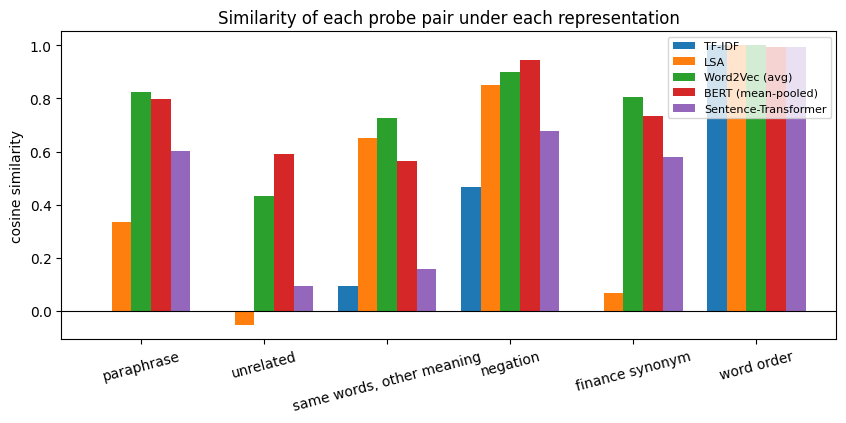

In [17]:
ax = summary.plot(kind="bar", figsize=(10, 4), rot=15, width=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("cosine similarity")
ax.set_title("Similarity of each probe pair under each representation")
ax.legend(loc="upper right", fontsize=8);

How to read it: for a representation to be useful for *search*, the paraphrase and finance-synonym bars must be
clearly above the unrelated bar, and the "same words, other meaning" bar should be low.
With only TF-IDF and LSA, none of those conditions is met at once. The word-order pair is a hard case for
every level: even contextual sentence embeddings often score "A bought B" and "B bought A" as
near-duplicates, which matters for questions like "who acquired whom".

# Same task, same split: does richer mean better?

All representations feed the same logistic regression on the same 80/20 split. Macro-F1 is the metric:
it weights the rare topics (`ship`, `interest`) as much as `earn` (see `01`).

In [18]:
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2, stratify=df["label"], random_state=RANDOM_STATE)
y = df["label"].to_numpy()
classification = {}

def evaluate(name, fit_transform):
    """
    fit_transform(train_texts, test_texts) -> (X_train, X_test). 
    The representation is fitted on the training texts only, so no test information leaks in
    """
    t0 = time.time()
    X_train, X_test = fit_transform([texts[i] for i in train_idx], [texts[i] for i in test_idx])
    encode_s = time.time() - t0
    clf = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_train, y[train_idx])
    pred = clf.predict(X_test)
    classification[name] = {
        "dims": X_train.shape[1],
        "macro_f1": round(f1_score(y[test_idx], pred, average="macro"), 3),
        "accuracy": round((pred == y[test_idx]).mean(), 3),
        "encode_seconds": round(encode_s, 1),
    }
    return pd.Series(classification[name], name=name)

In [19]:
def tfidf_features(train, test):
    v = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(train)
    return v.transform(train), v.transform(test)

def lsa_features(train, test):
    v = TfidfVectorizer(stop_words="english", min_df=3, sublinear_tf=True).fit(train)
    s = TruncatedSVD(150, random_state=RANDOM_STATE).fit(v.transform(train))
    return normalize(s.transform(v.transform(train))), normalize(s.transform(v.transform(test)))

evaluate("TF-IDF", tfidf_features)
evaluate("LSA (150 dims)", lsa_features)
pd.DataFrame.from_dict(classification, orient="index")

,dims,macro_f1,accuracy,encode_seconds
TF-IDF,53276,0.959,0.968,1.6
LSA (150 dims),150,0.959,0.972,1.2


In [20]:
# Word2Vec here was trained on all articles' text (no labels involved), so reusing it is not label leakage.
evaluate("Word2Vec (avg)", lambda tr, te: (w2v_encode(tr), w2v_encode(te)))

dims              150.000
macro_f1            0.954
accuracy            0.968
encode_seconds      1.300
Name: Word2Vec (avg), dtype: float64

In [21]:
# Slow on CPU: a full BERT forward pass per article (truncated to 256 tokens)
evaluate("BERT (mean-pooled)", lambda tr, te: (bert_encode(tr), bert_encode(te)))

dims              768.000
macro_f1            0.957
accuracy            0.971
encode_seconds    440.900
Name: BERT (mean-pooled), dtype: float64

In [22]:
evaluate("Sentence-Transformer", lambda tr, te: (sbert_encode(tr), sbert_encode(te)))

RuntimeError: MPS backend out of memory (MPS allocated: 1.02 GiB, other allocations: 8.05 GiB, max allowed: 9.07 GiB). Tried to allocate 8.91 MiB on private pool. Use PYTORCH_MPS_HIGH_WATERMARK_RATIO=0.0 to disable upper limit for memory allocations (may cause system failure).

In [23]:
results = pd.DataFrame.from_dict(classification, orient="index").sort_values("macro_f1", ascending=False)
results

,dims,macro_f1,accuracy,encode_seconds
TF-IDF,53276,0.959,0.968,1.6
LSA (150 dims),150,0.959,0.972,1.2
BERT (mean-pooled),768,0.957,0.971,440.9
Word2Vec (avg),150,0.954,0.968,1.3


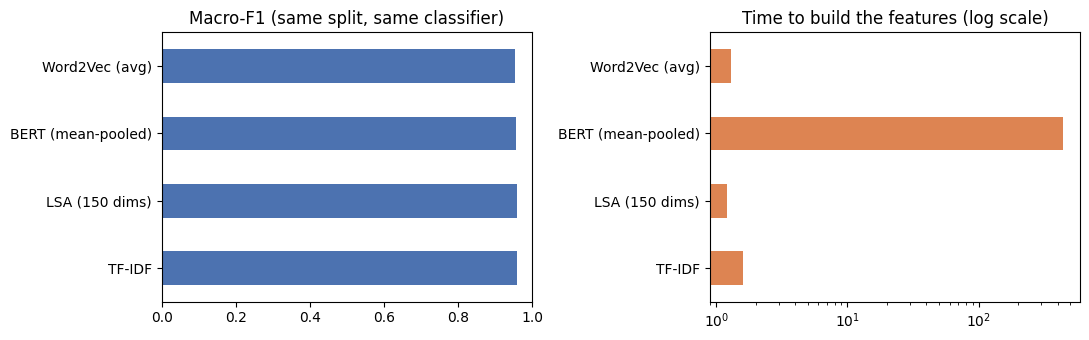

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
results["macro_f1"].plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_xlim(0, 1); axes[0].set_title("Macro-F1 (same split, same classifier)")
results["encode_seconds"].plot(kind="barh", ax=axes[1], color="#DD8452", logx=True)
axes[1].set_title("Time to build the features (log scale)")
plt.tight_layout()

All four representations achieve very similar classification performance (easy task, small dataset), see the `Classification_V1/` notebook where real differences are visible betweeen the representations with transformer embeddings and word2vec coming on top, with bigger disparities on the larger dataset.
LSA is preferable there not because it is dramatically more accurate, but because it provides comparable or slightly better results with only 150 dimensions and very low encoding cost. 
BERT’s marginal performance difference does not justify its substantially higher computational cost.

# What the document space looks like

PCA projection of each representation's test vectors, coloured by topic. Clear clusters mean the representation
separates topics on its own, before any classifier is trained.

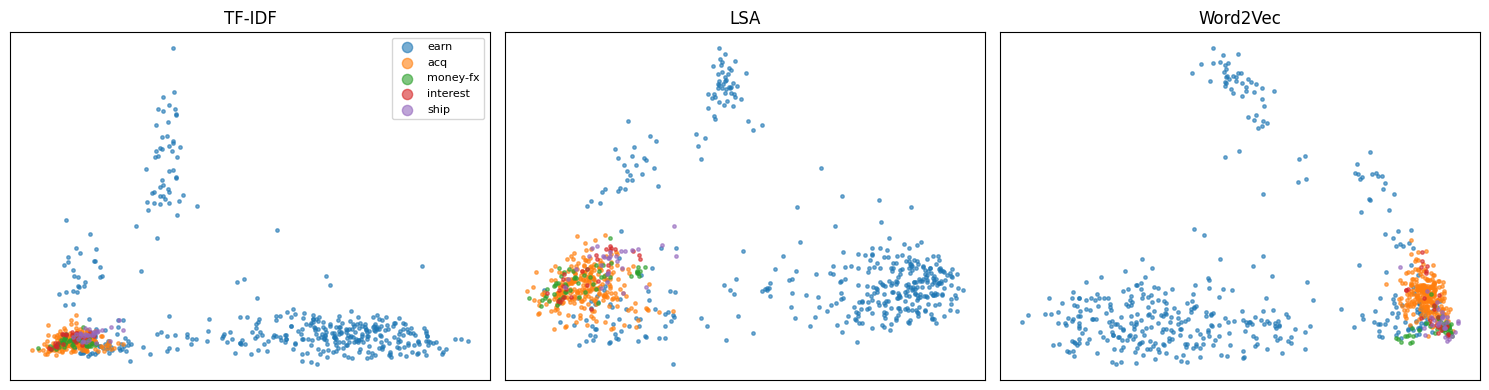

In [31]:
reps = {"TF-IDF": tfidf_features, 
        "LSA": lsa_features, 
        }
for name, fn in [("Word2Vec", lambda tr, te: (w2v_encode(tr), w2v_encode(te)))]:
    if "w2v" in globals():
        reps[name] = fn

sample = test_idx[:800]
fig, axes = plt.subplots(1, len(reps), figsize=(5 * len(reps), 4))
colors = dict(zip(TARGET_TOPICS, plt.cm.tab10.colors))
for ax, (name, fn) in zip(np.atleast_1d(axes), reps.items()):
    _, X = fn([texts[i] for i in train_idx], [texts[i] for i in sample])
    X = X.toarray() if sparse.issparse(X) else X
    xy = PCA(2, random_state=RANDOM_STATE).fit_transform(X)
    for topic in TARGET_TOPICS:
        m = y[sample] == topic
        ax.scatter(xy[m, 0], xy[m, 1], s=6, alpha=0.6, color=colors[topic], label=topic)
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
np.atleast_1d(axes)[0].legend(markerscale=3, fontsize=8)
plt.tight_layout()

In two dimensions only `earn` separates: earnings tables ("shr", "cts", "vs", "revs") are a genre of their own,
and even split into several sub-clusters (quarterly vs annual reports, profit vs loss). The other four topics
overlap almost completely here, yet the classifier still reaches 0.96 macro-F1: they are separable in the full
space, just not in its two largest directions. A 2D projection is a sanity check, not evidence of separability.

# Takeaways

- **TF-IDF is a very strong baseline here**: macro-F1 0.959 on the single-label subset, because Reuters
  topics are written in distinct vocabularies. It is also the only fully interpretable representation.
  Its blind spot is meaning: paraphrases share no words and score exactly zero.
- **LSA matches TF-IDF on classification (macro-F1 0.959) with 150 dimensions instead of ~53,000**, while
  explaining under 30% of the variance: the variance it discards is mostly irrelevant to topic. But its probe
  results show it is not a good *meaning* space either: it merges word senses and ignores negation.
  Good for compact features, not for search.
- **Word2Vec** learns word-level similarity but averaging discards order and dilutes negation, trained on a small corpus its vectors are noisy.
- **BERT** is the first representation that resolves polysemy (the *bank* matrix). 
Mean-pooled raw BERT, however, is not a good similarity space.
- **Sentence-Transformers** are trained for exactly that, which is why they are used for semantic search.
- **Richer is not automatically better for a given task.** Pick by measuring under identical conditions, and weigh the encoding-time column: on a keyword-driven task the cheapest representation can win.

If we refer to the `Classification_V1/` notebook, the differences between representations are more visible on the larger dataset, with transformer embeddings and Word2Vec coming on top.